1. **Nome(s):** Leonardo Silveira Kiepper

2. **Matrícula(s):** 2026140417

3. **E-mail(s) institucional(is):** leonardo.kiepper@edu.ufes.br

3. **Curso(s):** Doutorado em Ciência da Computação

4. **Link do seu Colab com suas soluções (para que o professor possa acessar e rodar o código):** https://colab.research.google.com/github/LeoKiepper/Ciencia-de-Dados/blob/main/trabalho1/T1_leonardo_kiepper.ipynb


In [49]:
%pip install itables
%pip install nltk
%pip install unidecode
%pip install scikit-learn
%pip install langdetect


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [50]:
import numpy as np
import pandas as pd # prática comum
from itables import show
from datetime import datetime
import nltk
#nltk.download('punkt')
nltk.download('punkt_tab')
from nltk import sent_tokenize, word_tokenize
import unidecode
import string
from nltk.corpus import stopwords
nltk.download('stopwords')
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from langdetect import detect, DetectorFactory, LangDetectException
import os
from sklearn.decomposition import TruncatedSVD

def descreve_dataset(df: pd.DataFrame):
    print(f"Número de livros: {len(df)}")
    print('')
    print(f"Quantos NaN em cada coluna: \n{df.isna().sum()}")
    print('')
    print("Autores distintos:", df['author'].nunique())
    if 'idioma' in df.columns: 
        print('')
        print('Quantidade de livros por idioma')   
        print(livros['idioma'].value_counts())
    # print(livros['author'].value_counts())    


[nltk_data] Downloading package punkt_tab to /home/Leo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/Leo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


`book_id` não contribuirá para exprimir uma relação com `genre`, pois é apenas um indexador no *dataset*, e não ‘promete’ nenhuma relação com o conteúdo do livro. Qualquer relação encontrada seria expúria, então será usado como *index* do DataFrame.

In [51]:
# Importa o dataset completo

livros = pd.read_csv('goodreads_books.csv').set_index('book_id')


# Descarta textos que não estão em inglês
DetectorFactory.seed = 0   # torna a detecção determinística

def idioma(texto):
    if not isinstance(texto, str) or not texto.strip():
        return None
    try:
        return detect(texto)
    except LangDetectException:
        return None


ARQ_IDIOMA = 'idiomas.csv'
if 'idioma' not in livros.columns:
    if os.path.exists(ARQ_IDIOMA):
        idiomas = pd.read_csv(ARQ_IDIOMA, index_col='book_id')['idioma']
        livros['idioma'] = idiomas.reindex(livros.index)
    else:
        livros['idioma'] = livros['description'].apply(idioma)
        livros['idioma'].to_csv(ARQ_IDIOMA)


livros['idioma'] = livros['description'].apply(idioma)
descreve_dataset(livros)

livros = livros[livros['idioma'] == 'en']

Número de livros: 25000

Quantos NaN em cada coluna: 
title                  0
author                 0
description            0
genre                  0
publication_year    5069
average_rating         0
ratings_count          0
num_pages           7273
idioma                 0
dtype: int64

Autores distintos: 17509

Quantidade de livros por idioma
idioma
en    24568
es      132
fr       82
de       48
pt       28
it       25
cy       24
id       19
nl       10
pl        8
tr        8
hr        7
sl        7
et        4
fi        4
da        4
hu        3
so        3
ro        3
cs        2
sv        2
af        2
ca        2
tl        1
lt        1
sk        1
sw        1
sq        1
Name: count, dtype: int64


In [52]:
show(livros.loc[:,livros.columns!='description'])

In [53]:
# semente = np.random.randint(0, 2**31)
# df=livros.sample(n=100, random_state=semente)

# A título de ensaio, pega uma fatia pequena, e fixa a semente com random_state
semente = 2003343720
# semente = np.random.randint(0, 2**31)
df=livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
descreve_dataset(df)
show(df)

Número de livros: 1000

Quantos NaN em cada coluna: 
title                 0
author                0
description           0
genre                 0
publication_year    211
average_rating        0
ratings_count         0
num_pages           307
dtype: int64

Autores distintos: 971


Aqui pode ser relevante analisar o titulo e a descrição, pois o titulo e a descrição carregam informações diferentes, e tem utilidades diferentes. A descrição é o que vende o livro para um leitor em potencial, e o titulo é o gancho que puxa a atenção; objetivos diferentes, que pedem estratégias e estilos de escrita diferentes.

Sobre pré-processamento textual, do material de aula:
>É uma boa prática seguir, ao menos, os seguintes passos:
>1. Dividir o texto em *tokens*
>2. Converter o texto para letras minúsculas
>3. Remover símbolos de pontuação de cada *token*
>4. Converter caracteres especiais (passo discutível e necessidade deve ser analisada)
>5. Remover *tokens* que não são palavras
>6. Remover *tokens* que são *stop words*


In [54]:

def preprocessamento(df: pd.Series):
    # 1. Dividir o texto em tokens
    tokens = word_tokenize(df)  
    # tokens = sent_tokenize(df)

    # 2. Converter o texto para letras minúsculas
    tokens = [w.lower() for w in tokens]

    # 3. Remover símbolos de pontuação de cada token
    table = str.maketrans('', '', string.punctuation)
    tokens = [w.translate(table) for w in tokens]

    # 4. Converter caracteres especiais
    # tokens = [unidecode.unidecode(w).lower() for w in tokens]

    # 5. Remover tokens que não são palavras
    words = [word for word in tokens if word.isalpha()]

    # 6. Remover tokens que são stop words
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if not word in stop_words]
    
    # Stemming
    # porter = PorterStemmer()
    # stemmed = [porter.stem(word) for word in words]
    # words = stemmed
    
    return words

show(df['description'].apply(preprocessamento))

In [55]:
def calculaX(x: pd.Series):
    vectorizer = TfidfVectorizer(analyzer=preprocessamento)
    X = vectorizer.fit_transform(x)
    return pd.DataFrame.sparse.from_spmatrix(
        X,
        index=x.index,
        columns=vectorizer.get_feature_names_out()
    ).astype(pd.SparseDtype('float64', 0))


X_desc = calculaX(df['description'])
show(X_desc)

X_title = calculaX(df['title'])
show(X_title)

In [56]:
def encontra_token_max(X: pd.DataFrame) -> str:
    return X.max(axis=0).idxmax()
print(f"Tamanho do corpus, descrição: {len(X_desc.columns)}.")
print(f"\tTF-IDF máximo, descrição: {X_desc.max().max()}")
print(f"\ttoken com TF-IDF máximo: {encontra_token_max(X_desc)}")
print(f"Tamanho do corpus, título: {len(X_title.columns)}.")
print(f"\tTF-IDF máximo, título: {X_title.max().max()}")
print(f"\ttoken com TF-IDF máximo: {encontra_token_max(X_title)}")


Tamanho do corpus, descrição: 16790.
	TF-IDF máximo, descrição: 0.7852975938603638
	token com TF-IDF máximo: clare
Tamanho do corpus, título: 2130.
	TF-IDF máximo, título: 1.0
	token com TF-IDF máximo: academie


A estratégia de vetorizar pelo processo codificado nas células acima não é aplicável a todas as colunas do *dataset*. Por exemplo, a coluna Autor pode ser vista como um dado categórico, e precisaria de um tratamento diferente. 

As células acimas, responsáveis por vetorizar a descrição e o título, foram rodadas para o *dataset* completo para saber a dimensão máxima da matriz X:

>```
>Tamanho do corpus, descrição: 112003.
>	TF-IDF máximo, descrição: 0.9311781254312337
>	token com TF-IDF máximo: waldo
>Tamanho do corpus, título: 19157.
>	TF-IDF máximo, título: 1.0
>	token com TF-IDF máximo: abandon
>```

Em comparação, as demais características presentes no *dataset*, descontando o `genre`, `description`, `title` e `book_id`, somam 5 dimensões à análise sobre o *dataset*. Dito isso, não faz sentido sujeitar essas dimensões ao algorítimo de PCA, junto com as matrizes `X`. O ganho seria comparativamente desprezível, e poderia haver perda de informação desproporcional.

Portanto, deseja-se fazer uma redução de dimensionalidade sobre `X_desc` e `X_title` separadamente. Desta forma, além de reduzir a dimensão tão somente sobre o que inviabiliza a análise, o algorítimo trabalha sobre dados de mesma natureza — e automaticamente na mesma escala — e assim, a perda de intuição sobre as grandezas dos dados é menos problemática.

Deseja-se fazer o PCA aplicando SVD truncado sobre cada matriz X, produzindo um resultado gantidamente equivalente (https://scikit-learn.org/stable/modules/decomposition.html#lsa). Para selecionar o número de componentes do PCA (aqui, implementado com SVD), é necessário seguir um procedimento sistemático, considerando o erro de aproximação, análogo a como é feito com PCA

Sobre o método geral para determinação do $k$:

>##### Do material de aula sobre PCA:
>**Entrada:**
>1. Matriz de dados $\mathbf{X} \in \mathbb{R}^{n \times d}$
>2. $0 \le \alpha \le 1$, fração da variância total a ser considerada 
><br><br>
>
>**Passos:**
>
>3. $\mathbf{Z} \leftarrow$ matriz $\mathbf{X}$ após centralização/pré-processamento
>4. $\Sigma \leftarrow \frac{\mathbf{Z}^T\mathbf{Z}}{n}$
>5. $\lambda_1, \dots, \lambda_d \leftarrow$ autovalores de $\Sigma$ ordenados decrescentemente
>6. $\mathbf{u}_1, \dots, \mathbf{u}_d \leftarrow$ autovetores de $\Sigma$ ($\mathbf{u_i}$ está associado a $\lambda_i$)
>7. $f(k) \leftarrow \frac{\sum_{i=1}^k\lambda_i}{\sum_{i=1}^d\lambda_i}$, para $k = 1, \dots, d$
>8. Escolha o menor $k$ tal que $f(k) \ge \alpha$
>9. $\mathbf{U}_k \leftarrow$ matriz cujas colunas são $\mathbf{u}_1, \dots, \mathbf{u}_k$
><br>
>
>**Saída:**
>
>10. Retorne $\mathbf{Z}\mathbf{U}_k$

SVD entrega os valores $\sigma_k$ já ordenados, e a matriz aproximada de *rank* $k$, $\mathbf{X}_\text{k}$, é dada por: $$ \mathbf{X}_k = \mathbf{U}_k\mathbf{S}_k\mathbf{V}_k^T.$$

Dito isso, escolher o $k$ significa trazer a norma de Frobenius $$\Vert\mathbf{X} - \mathbf{X}_k\Vert_F = \sqrt{\sum_{i=k+1}^r\sigma^2_i}.$$ para um patamar aceitável, definido em função do $\alpha$, descrito acima


# Validação do PCA

Deseja-se aplicar O SVD truncado sobre a matriz esparsa, o que permite tratar matrizes grandes em tempo de processamento razoável. A título de teste de sanidade, é fixada uma amostra pequena do dataset completo, que é sujeitada ao SVD truncado, SVD completo e PCA, e os resultados são comparados para demonstrar que são equivalentes, como esperado. Depois, nos três algorítimos, o procedimento de seleção do $k$ é feito para um $alpha$ pré-selecionado, e novamente, as matrizes reduzidas são comparadas.

In [67]:
#@title Salva um df amostrado
ARQ_AMOSTRA = f'amostra_n{len(df)}_seed{semente}.csv'

df_salvar = df.copy()
df_salvar.to_csv(ARQ_AMOSTRA)          # index=True por padrão, grava book_id
print(f'Amostra salva em {ARQ_AMOSTRA}')


Amostra salva em amostra_n1000_seed2003343720.csv


In [68]:
#@title Carrega um df amostrado e calcula a matriz TF-IDF a partir da coluna description
REPO_RAW = 'https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/'
ARQ_AMOSTRA = 'amostra_n1000_seed2003343720.csv'

df = pd.read_csv(REPO_RAW + ARQ_AMOSTRA, index_col='book_id')

descreve_dataset(df)
X = calculaX(df['description'])
ALPHA = 0.8


Número de livros: 1000

Quantos NaN em cada coluna: 
title                 0
author                0
description           0
genre                 0
publication_year    211
average_rating        0
ratings_count         0
num_pages           307
tokens                0
dtype: int64

Autores distintos: 971


In [78]:
import scipy.sparse as sp
import scipy.linalg
from scipy.sparse.linalg import norm as spnorm
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

def para_esparsa(X):
    if isinstance(X, pd.DataFrame):
        X = X.sparse.to_coo()
    return sp.csr_matrix(X, dtype=np.float64)

def padroniza(X):
    """Densifica e aplica StandardScaler com média 0 e desvio 1 por coluna."""
    Xd = para_esparsa(X).toarray()
    return StandardScaler(with_mean=True, with_std=True).fit_transform(Xd)

def seleciona_k(s, Anorm2, alpha):
    """Menor k com fração de variância não explicada <= 1 - alpha."""
    nao_explicada = np.maximum(Anorm2 - np.cumsum(s**2), 0) / Anorm2   # = 1 - f(k)
    limiar = 1 - alpha
    atinge = np.flatnonzero(nao_explicada <= limiar)
    k_alpha = int(atinge[0]) + 1 if len(atinge) else None
    return nao_explicada, limiar, k_alpha


def plota_espectro(s, Anorm2, alpha, rotulo):
    """Gráficos 1 e 2 para um vetor s de valores singulares em ordem decrescente."""
    k = np.arange(1, len(s) + 1)
    err_rel, limiar, k_alpha = seleciona_k(s, Anorm2, alpha)

    # Gráfico 1: valores singulares
    plt.figure(figsize=(6, 4))
    plt.plot(k, s, '.-')
    if k_alpha: plt.axvline(k_alpha, ls='--', color='gray', label=fr'$k_\alpha$ = {k_alpha}')
    plt.xlabel(r'$k$', size=16); plt.ylabel(r'$\sigma_k$', size=16)
    plt.ylim(ymin=0)
    plt.title(f'Singular Values – {rotulo}', size=16)
    plt.legend()

    # Gráfico 2: erro relativo de Frobenius
    plt.figure(figsize=(6, 4))
    plt.plot(k, err_rel, '.-')
    plt.axhline(limiar, ls='--', color='red', label=fr'$1-\alpha$, $\alpha$ = {alpha}')
    if k_alpha: plt.axvline(k_alpha, ls='--', color='gray', label=fr'$k_\alpha$ = {k_alpha}')
    plt.ylim([0, 1])
    plt.xlabel(r'$k$', size=16); plt.ylabel(r'$\Vert X - X_k\Vert_F^2 \,/\, \Vert X\Vert_F^2$', size=16)
    plt.title(f'Fração da variância não explicada – {rotulo}', size=16)
    plt.legend()

    print(f'{rotulo}: k para alpha={alpha} -> {k_alpha}')
    return k_alpha


PCA: k para alpha=0.8 -> 617


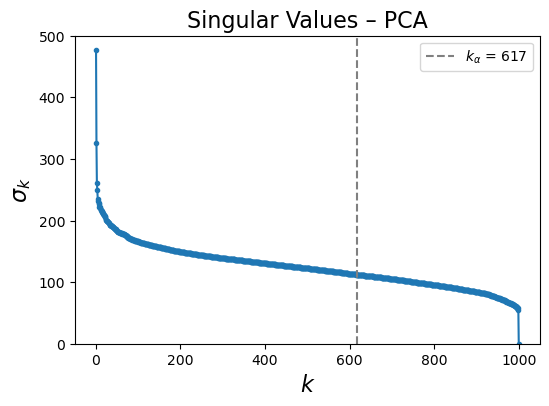

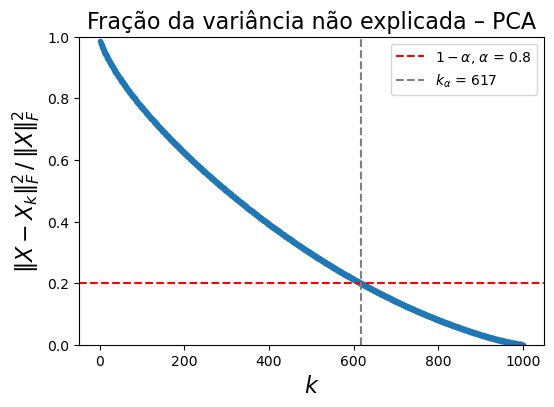

In [79]:
#@title PCA (StandardScaler + PCA completo)
Z = padroniza(X)
pca = PCA(svd_solver='full').fit(Z)          # n_components=None -> todos os min(n, d)
s_pca = pca.singular_values_
k_pca = plota_espectro(s_pca, np.linalg.norm(Z)**2, ALPHA, 'PCA')


SVD completo: k para alpha=0.8 -> 617


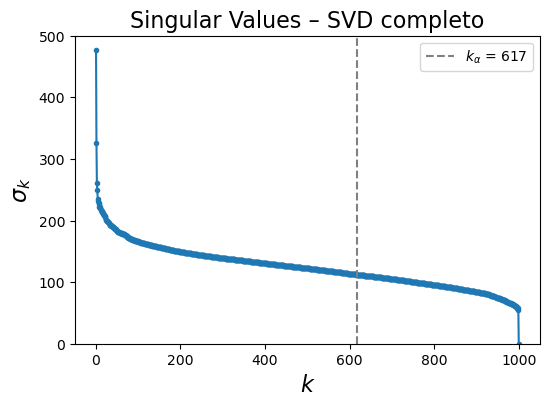

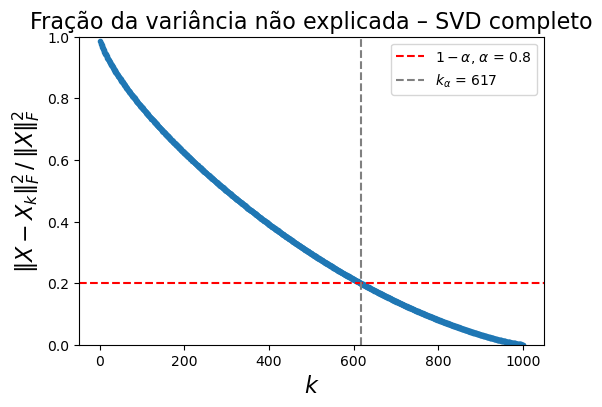

In [80]:
#@title SVD completo (StandardScaler + scipy.linalg.svd)
Z = padroniza(X)
_, s_svd, _ = scipy.linalg.svd(Z, full_matrices=False, lapack_driver='gesvd')
k_svd = plota_espectro(s_svd, np.linalg.norm(Z)**2, ALPHA, 'SVD completo')


SVD truncado sobre Z: k para alpha=0.8 -> 617


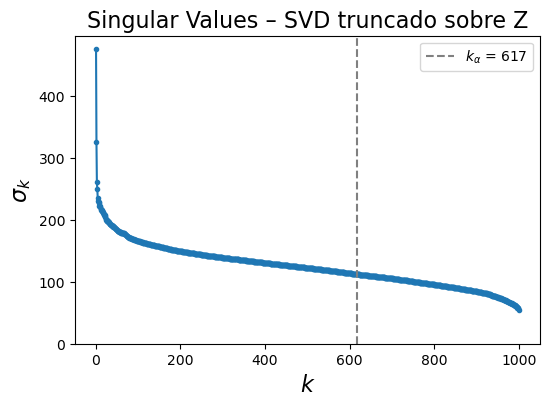

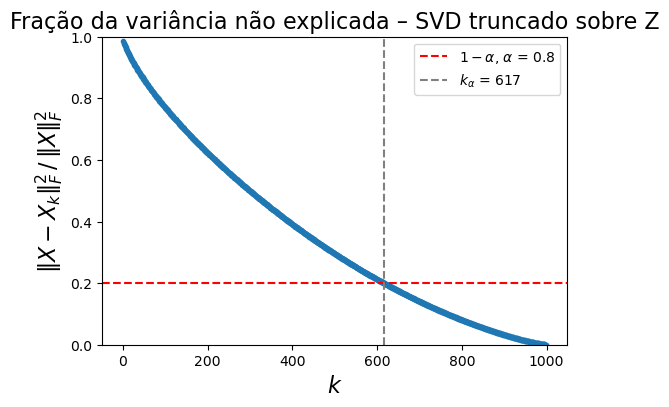

In [81]:
#@title SVD truncado sobre Z (mesma entrada do PCA e do SVD completo)
Z = padroniza(X)
kmax_z = min(KMAX, min(Z.shape) - 1)
svd_z = TruncatedSVD(n_components=kmax_z, random_state=semente).fit(Z)
s_trunc_z = svd_z.singular_values_
k_trunc_z = plota_espectro(s_trunc_z, np.linalg.norm(Z)**2, ALPHA, 'SVD truncado sobre Z')


SVD truncado: k para alpha=0.8 -> 677


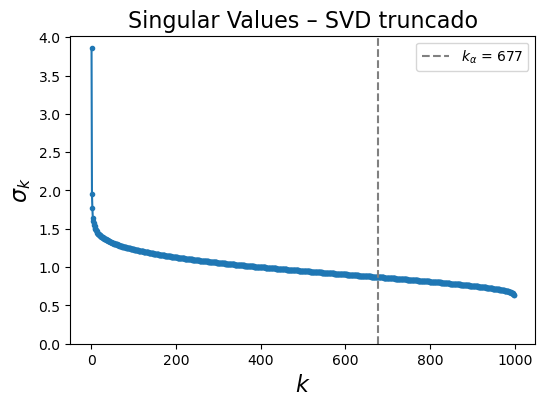

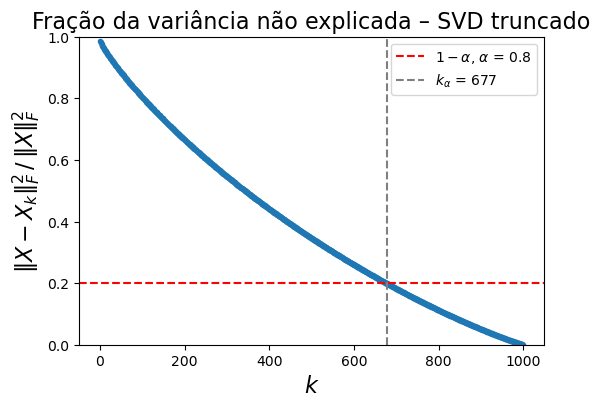

In [82]:
#@title SVD truncado (matriz esparsa, sem normalização)
KMAX = X.shape[0]
Xs = para_esparsa(X)
kmax = min(KMAX, min(Xs.shape) - 1)
svd = TruncatedSVD(n_components=kmax, random_state=semente).fit(Xs)
s_trunc = svd.singular_values_
k_trunc = plota_espectro(s_trunc, spnorm(Xs)**2, ALPHA, 'SVD truncado')


In [83]:
#@title Comparação entre os métodos
def diff_max(a, b):
    n = min(len(a), len(b))
    return np.abs(a[:n] - b[:n]).max()

print('Mesma entrada Z:')
print(f'  max |s_pca     - s_svd|        = {diff_max(s_pca, s_svd):.2e}')
print(f'  max |s_trunc_z - s_svd[:kmax]| = {diff_max(s_trunc_z, s_svd):.2e}')
print(f'  PCA == SVD completo:            {np.allclose(s_pca, s_svd, rtol=1e-5, atol=1e-8)}')
print(f'  SVD truncado(Z) == SVD completo: {np.allclose(s_trunc_z, s_svd[:len(s_trunc_z)], rtol=1e-5, atol=1e-8)}')

print('\nEntradas diferentes (X crua vs Z):')
print(f'  ||X||_F^2 = {spnorm(Xs)**2:.1f}   ||Z||_F^2 = {np.linalg.norm(Z)**2:.1f}')
print(f'  max |s_trunc - s_svd[:kmax]|   = {diff_max(s_trunc, s_svd):.2e}')

print('\nk por método, alpha =', ALPHA)
print(pd.Series({
    'PCA (Z)':              k_pca,
    'SVD completo (Z)':     k_svd,
    'SVD truncado (Z)':     k_trunc_z,
    'SVD truncado (X crua)': k_trunc,
}, name='k'))


Mesma entrada Z:
  max |s_pca     - s_svd|        = 3.18e-12
  max |s_trunc_z - s_svd[:kmax]| = 3.21e-12
  PCA == SVD completo:            True
  SVD truncado(Z) == SVD completo: True

Entradas diferentes (X crua vs Z):
  ||X||_F^2 = 1000.0   ||Z||_F^2 = 16790000.0
  max |s_trunc - s_svd[:kmax]|   = 4.72e+02

k por método, alpha = 0.8
PCA (Z)                  617
SVD completo (Z)         617
SVD truncado (Z)         617
SVD truncado (X crua)    677
Name: k, dtype: int64
